In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("mlg-ulb/creditcardfraud")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'creditcardfraud' dataset.
Path to dataset files: /kaggle/input/creditcardfraud


In [2]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
print(os.listdir(path))


['creditcard.csv']


In [3]:
file_path = os.path.join(path, "creditcard.csv")

In [4]:
data =  pd.read_csv(file_path)

In [5]:
#data.head()
#data.info()



#Day 1:
#data comtains 284807 rows and 31 columns
#most columns are provided as numberic representation of values to protect the privacy
#only labeled columns are Time, Amount and Class. 
#Time = Number of seconds elapsed between the transaction and the first transaction in the dataset.
#Amount = ? 
#Class = 1 if frauduelent transaction and 0 if not
#data.isnull().sum()
#Doesn't seem to have any null values
#data.describe()
#data['Class'].value_counts()

In [6]:

fraud = data[data['Class'] == 1]
#fraud
#Total frauds are 186 in 284807 roughly 0.07%
#No timestamp


In [7]:
#data.info()
#data['Class'].value_counts(normalize=True)*100
#data.duplicated()
#data['Time'].is_monotonic_increasing

Text(0, 0.5, 'Number of transactions')

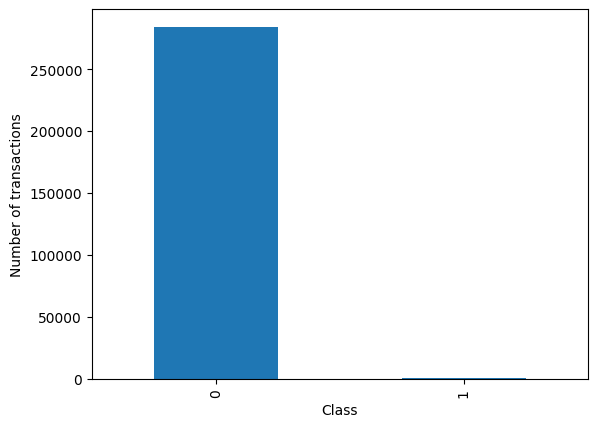

In [8]:
data['Class'].value_counts().plot(kind='bar')
plt.xlabel("Class")
plt.ylabel("Number of transactions")

In [9]:
data.groupby("Class")["Amount"].describe()

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,284315.0,88.291022,250.105092,0.0,5.65,22.00,77.05,25691.16
1,492.0,122.211321,256.683288,0.0,1.00,9.25,105.89,2125.87


Text(0, 0.5, 'Amount')

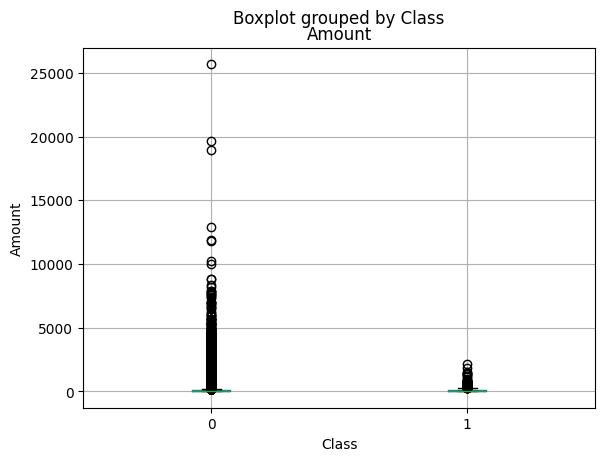

In [10]:
data.boxplot(column = "Amount", by = "Class")
plt.xlabel("Class")
plt.ylabel("Amount")

In [11]:
data.groupby("Class")["Time"].describe()


,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,284315.0,94838.202258,47484.015786,0.0,54230.0,84711.0,139333.0,172792.0
1,492.0,80746.806911,47835.365138,406.0,41241.5,75568.5,128483.0,170348.0


Text(0, 0.5, 'Time')

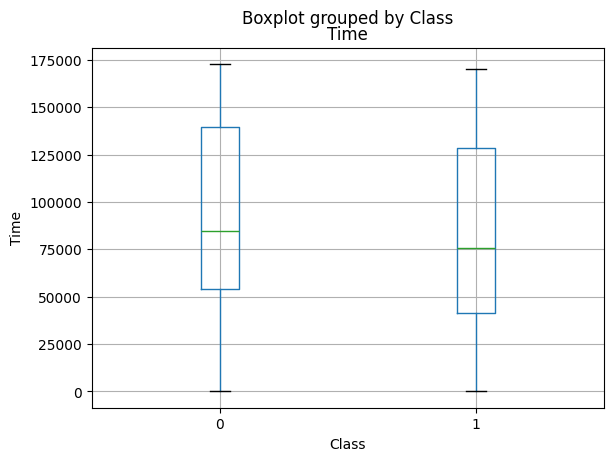

In [12]:
data.boxplot(column = "Time", by = "Class")
plt.xlabel("Class")
plt.ylabel("Time")

In [13]:
data.groupby("Class").mean()
data.groupby("Class").median()


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount
Class,,,,,,,,,,,,,,,,,,,,,
0,84711.0,0.020023,0.064070,0.182158,-0.022405,-0.053457,-0.273123,0.041138,0.022041,-0.049964,...,-0.062646,-0.029821,0.006736,-0.011147,0.041082,0.016417,-0.052227,0.001230,0.011199,22.00
1,75568.5,-2.342497,2.717869,-5.075257,4.177147,-1.522962,-1.424616,-3.034402,0.621508,-2.208768,...,0.284693,0.592146,0.048434,-0.073135,-0.060795,0.088371,0.004321,0.394926,0.146344,9.25


In [14]:
coorelations = data.corr()["Class"].sort_values()
print(coorelations)

V17      -0.326481
V14      -0.302544
V12      -0.260593
V10      -0.216883
V16      -0.196539
V3       -0.192961
V7       -0.187257
V18      -0.111485
V1       -0.101347
V9       -0.097733
V5       -0.094974
V6       -0.043643
Time     -0.012323
V24      -0.007221
V13      -0.004570
V15      -0.004223
V23      -0.002685
V22       0.000805
V25       0.003308
V26       0.004455
Amount    0.005632
V28       0.009536
V27       0.017580
V8        0.019875
V20       0.020090
V19       0.034783
V21       0.040413
V2        0.091289
V4        0.133447
V11       0.154876
Class     1.000000
Name: Class, dtype: float64


In [15]:
corr = data.corr()["Class"].drop("Class")
top_features = corr.abs().sort_values(ascending=False).head(5)
print(top_features)

V17    0.326481
V14    0.302544
V12    0.260593
V10    0.216883
V16    0.196539
Name: Class, dtype: float64


Text(0, 0.5, 'V17')

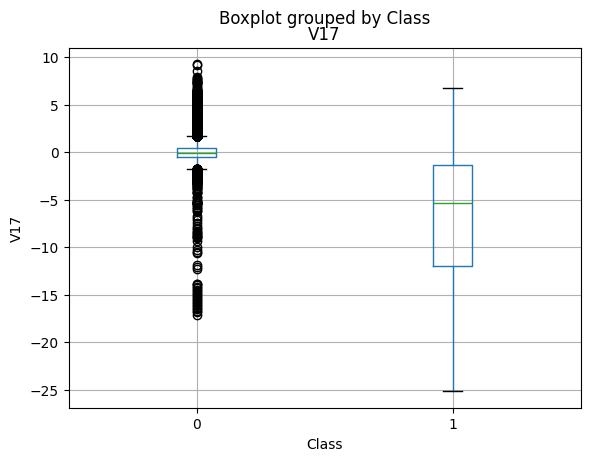

In [16]:
data.boxplot(column = 'V17', by = "Class")
plt.xlabel("Class")
plt.ylabel("V17")

Text(0, 0.5, 'V14')

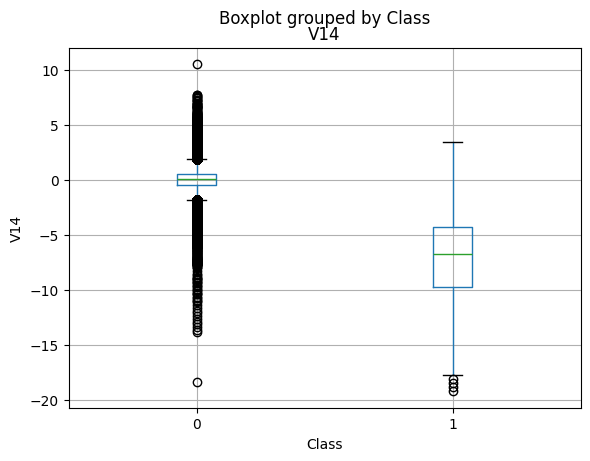

In [17]:
data.boxplot(column = 'V14', by = "Class")
plt.xlabel("Class")
plt.ylabel("V14")

Text(0, 0.5, 'V16')

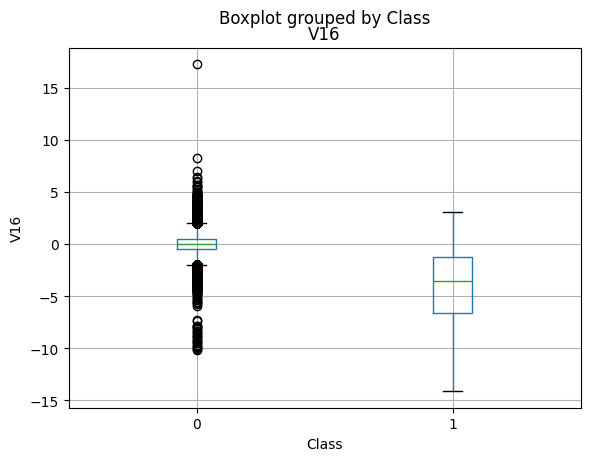

In [18]:
data.boxplot(column = 'V16', by = "Class")
plt.xlabel("Class")
plt.ylabel("V16")

Text(0, 0.5, 'V12')

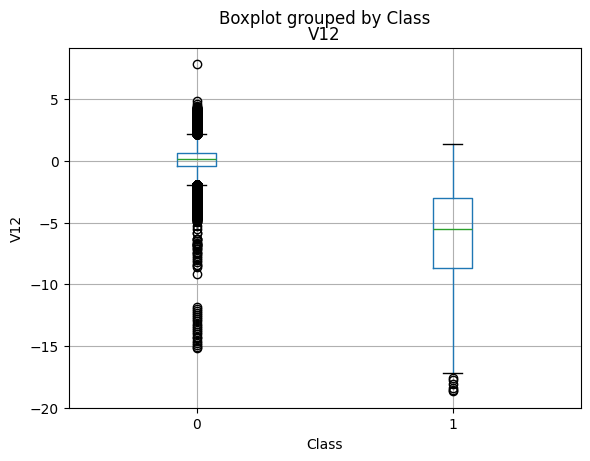

In [19]:
data.boxplot(column = 'V12', by = "Class")
plt.xlabel("Class")
plt.ylabel("V12")

Text(0, 0.5, 'V10')

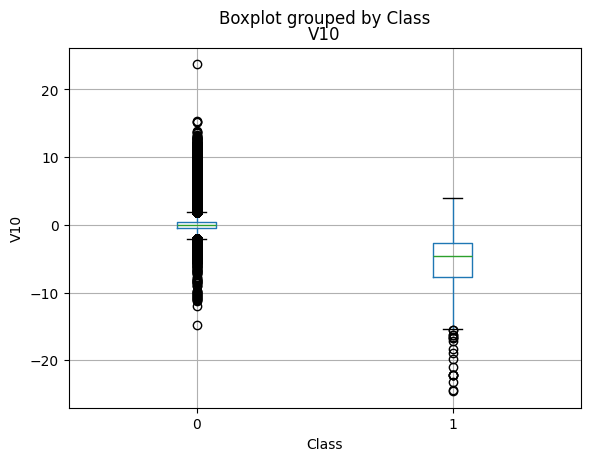

In [20]:
data.boxplot(column = 'V10', by = "Class")
plt.xlabel("Class")
plt.ylabel("V10")

In [21]:
#Day 2:
#The data is terribaly imbalanced
#The boxplot of amount and class doesn't have much difference in median
#One usefull thing gained. BoxPlot shows fraud transactions generally have lower median as compared to top coorelated columns like v17.
#All the above graphs shows a little dependecy of fraud calls on these columns

In [22]:
X = data.drop("Class", axis = 1)
Y = data["Class"]

In [23]:
print(X.shape, Y.shape)

(284807, 30) (284807,)


In [24]:
from sklearn.model_selection import train_test_split


In [25]:
X_train, X_test, Y_train, Y_test = train_test_split(X,Y, test_size=0.2, train_size=0.8, random_state=42, stratify=Y)

In [26]:
print(Y_train.value_counts())
print(Y_test.value_counts())

Class
0    227451
1       394
Name: count, dtype: int64
Class
0    56864
1       98
Name: count, dtype: int64


In [27]:
print("Class" in X)

False


In [28]:
X.describe().T[["min", "max"]]

,min,max
Time,0.000000,172792.000000
V1,-56.407510,2.454930
V2,-72.715728,22.057729
V3,-48.325589,9.382558
V4,-5.683171,16.875344
V5,-113.743307,34.801666
V6,-26.160506,73.301626
V7,-43.557242,120.589494
V8,-73.216718,20.007208
V9,-13.434066,15.594995


In [29]:
# Day 3
# data was split in X and Y
# X containing all feature except Target
# Y containing only target i.e Class
# Checked for data leckage
# Also Scale of all fearures is a bit wonky, might need fixing i.e scaling

In [30]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

In [31]:
model = LogisticRegression(max_iter=1000)
# Different types of solvers are present


In [32]:


# For Day 6 uncomment below

X_train["LogAmount"] = np.log1p(X_train["Amount"])
X_test["LogAmount"] = np.log1p(X_test["Amount"])

# print(X_train[["Amount", "LogAmount"]].head())
# print("____________________________")
# print(X_train[["Amount", "LogAmount"]].describe())
# print(X_train[["Time", "Amount", "LogAmount"]].describe())

scaler = StandardScaler()

columns_to_scale = ["Time", "Amount", "LogAmount"]

# Fit only on training data
X_train[columns_to_scale] = scaler.fit_transform(
    X_train[columns_to_scale]
)

# Transform test data using the same scaler
X_test[columns_to_scale] = scaler.transform(
    X_test[columns_to_scale]
)

In [33]:
model.fit(X_train,Y_train)

LogisticRegression(max_iter=1000)

In [34]:
y_pred = model.predict(X_test)
print(y_pred[:25])

[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [35]:
from sklearn.metrics import accuracy_score
print(accuracy_score(Y_test, y_pred))

0.9991748885221726


In [36]:
#The upper logistic regression gave 99% accuracy... but it was trained on very very imbalanced data so, 
# it will say most of the calls aren't fradulent
# That's why we cannot say this is a very good model just based on this accuracy score. 

In [37]:
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score, average_precision_score
cof_mat = confusion_matrix(Y_test,y_pred)
cf_rp = classification_report(Y_test,y_pred) 
print(cof_mat)
print(cf_rp)

[[56851    13]
 [   34    64]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.83      0.65      0.73        98

    accuracy                           1.00     56962
   macro avg       0.92      0.83      0.87     56962
weighted avg       1.00      1.00      1.00     56962



In [38]:
#Day 4 & 5:
# Baseline Logistic Regression:
# Logistic Regression achieved 83% precision and 64% recall for the fraud class on the held-out test set,
# detecting 63 of 98 fraudulent transactions while generating 13 false positives.
# accuracy is still 1 which is meaningless here due to class imbalence, hence focus more on recall and precision

In [39]:
roc_auc = roc_auc_score( Y_test, y_pred)
avg_pre = average_precision_score(Y_test,y_pred )
print("ROC AUC: ", roc_auc)
print("PR AUC: ", avg_pre)

ROC AUC:  0.8264163044227257
PR AUC:  0.5434010237950423


In [40]:
# Now we see that ROC AUC (Reciever Operating Characteristic Area Under Curve) i.e roc_auc_score gives 82% which is good, it's a decent model that can classify
# But PR AUC (Precision Recall Area Under curve) i.e averarage_precision_score gives ~54% which is low and means model can be optimised to raised that number.
# Rely on both metrics for a better understanding of model state. 

In [41]:
Log_Reg = {
    'ROC AUC': roc_auc,
    'PR AUC' : avg_pre,
    'Classification_Report' : cf_rp,
    'Confusion_MAtrix' : cof_mat
    }
Log_Reg

{'ROC AUC': np.float64(0.8264163044227257),
 'PR AUC': np.float64(0.5434010237950423),
 'Classification_Report': '              precision    recall  f1-score   support\n\n           0       1.00      1.00      1.00     56864\n           1       0.83      0.65      0.73        98\n\n    accuracy                           1.00     56962\n   macro avg       0.92      0.83      0.87     56962\nweighted avg       1.00      1.00      1.00     56962\n',
 'Confusion_MAtrix': array([[56851,    13],
        [   34,    64]])}

In [42]:
# Day 6:
# Feature engineering:
# - Added LogAmount = log1p(Amount)
# - Applied transformation before scaling
# - LogAmount slightly improved model performance

# Baseline:
# ROC-AUC = 0.8213
# PR-AUC  = 0.5335

# Feature engineered:
# ROC-AUC = 0.8264
# PR-AUC  = 0.5434

# Conclusion:
# Log-transformed transaction amount provided a modest improvement.

In [43]:
from sklearn.ensemble import RandomForestClassifier
rnd_for_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)

In [44]:
rnd_for_model.fit(X_train, Y_train)

RandomForestClassifier(n_jobs=-1, random_state=42)

In [45]:
y_pred1 = rnd_for_model.predict(X_test)
y_prob1 = rnd_for_model.predict_proba(X_test)[:,1]
print(y_pred)
print(y_prob1)

[0 0 0 ... 0 0 0]
[0.   0.   0.02 ... 0.   0.   0.  ]


In [46]:
conf_matrix_rf = confusion_matrix(Y_test, y_pred1)
cf_rp_rf = classification_report(Y_test,y_pred1)
roc_auc_rf = roc_auc_score(Y_test, y_prob1)
avg_pre_rf = average_precision_score(Y_test, y_prob1)


In [47]:
Random_Forest = {
    'ROC AUC': roc_auc_rf,
    'PR AUC' : avg_pre_rf,
    'Classification_Report' : cf_rp_rf,
    'Confusion_MAtrix' : conf_matrix_rf
    }
Random_Forest

{'ROC AUC': np.float64(0.952845062476313),
 'PR AUC': np.float64(0.8761509607136012),
 'Classification_Report': '              precision    recall  f1-score   support\n\n           0       1.00      1.00      1.00     56864\n           1       0.95      0.82      0.88        98\n\n    accuracy                           1.00     56962\n   macro avg       0.98      0.91      0.94     56962\nweighted avg       1.00      1.00      1.00     56962\n',
 'Confusion_MAtrix': array([[56860,     4],
        [   18,    80]])}

In [48]:
Log_Reg

{'ROC AUC': np.float64(0.8264163044227257),
 'PR AUC': np.float64(0.5434010237950423),
 'Classification_Report': '              precision    recall  f1-score   support\n\n           0       1.00      1.00      1.00     56864\n           1       0.83      0.65      0.73        98\n\n    accuracy                           1.00     56962\n   macro avg       0.92      0.83      0.87     56962\nweighted avg       1.00      1.00      1.00     56962\n',
 'Confusion_MAtrix': array([[56851,    13],
        [   34,    64]])}

In [49]:
# Day 7:
# Roc Auc Random forest > Log_Reg
# Pr Auc Random forest > Log_reg and also Comparable to Roc Auc
# Fraud precision and recall Random forest > Log_reg
# Model train time Log_Reg (1.23 sec) << Random forest (4 min 3 secs)
# Ups and down


In [50]:
from xgboost import XGBClassifier

In [51]:
xg_boost_cf = XGBClassifier( n_estimators=100,
    max_depth=5,
    learning_rate=0.1,
    random_state=42,
    n_jobs=-1,
    eval_metric = 'logloss')

In [52]:
xg_boost_cf.fit(X_train, Y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=5, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=100, n_jobs=-1,
              num_parallel_tree=None, ...)

In [53]:
xg_pred = xg_boost_cf.predict(X_test)
xg_prob = xg_boost_cf.predict_proba(X_test)[:,1]

In [54]:
xg_con_matrix = confusion_matrix(Y_test, y_pred)
xg_cls_rp = classification_report(Y_test, y_pred)
xg_roc = roc_auc_score(Y_test, xg_prob)
xg_avg_pr = average_precision_score(Y_test, xg_prob)

XG_Boost = {"XG_Conf": xg_con_matrix,
            "XGClassi": xg_cls_rp,
            "XG_ROC" : xg_roc,
            "XG_AVG_PRE": xg_avg_pr
            }

In [55]:
print(xg_con_matrix)
print(xg_cls_rp)
print(xg_roc)
print(xg_avg_pr)

[[56851    13]
 [   34    64]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.83      0.65      0.73        98

    accuracy                           1.00     56962
   macro avg       0.92      0.83      0.87     56962
weighted avg       1.00      1.00      1.00     56962

0.9611983264042816
0.8253082526014356


In [56]:
feature_importance = pd.Series(
    xg_boost_cf.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print(feature_importance.head(15))

V14       0.814251
V7        0.081761
V17       0.009988
V4        0.008706
V8        0.006494
V10       0.005849
V12       0.005459
V11       0.004576
V27       0.004557
V28       0.004340
Amount    0.003847
V19       0.003600
V26       0.003220
V16       0.003163
V13       0.003153
dtype: float32


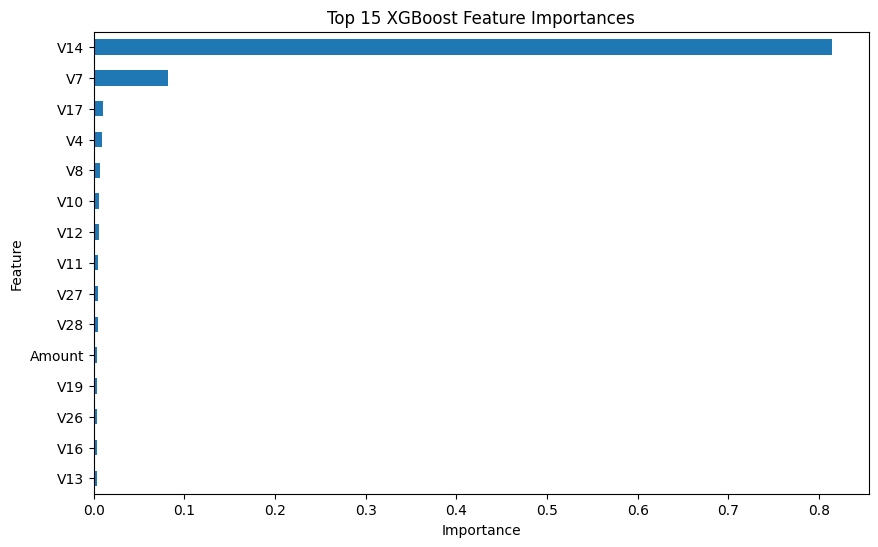

In [57]:
plt.figure(figsize=(10, 6))

feature_importance.head(15).sort_values().plot(kind="barh")

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 15 XGBoost Feature Importances")

plt.show()


In [58]:
data.groupby("Class")["V14"].describe()


,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,284315.0,0.012064,0.897007,-18.392091,-0.422453,0.051947,0.494104,10.526766
1,492.0,-6.971723,4.278940,-19.214325,-9.692723,-6.729720,-4.282821,3.442422


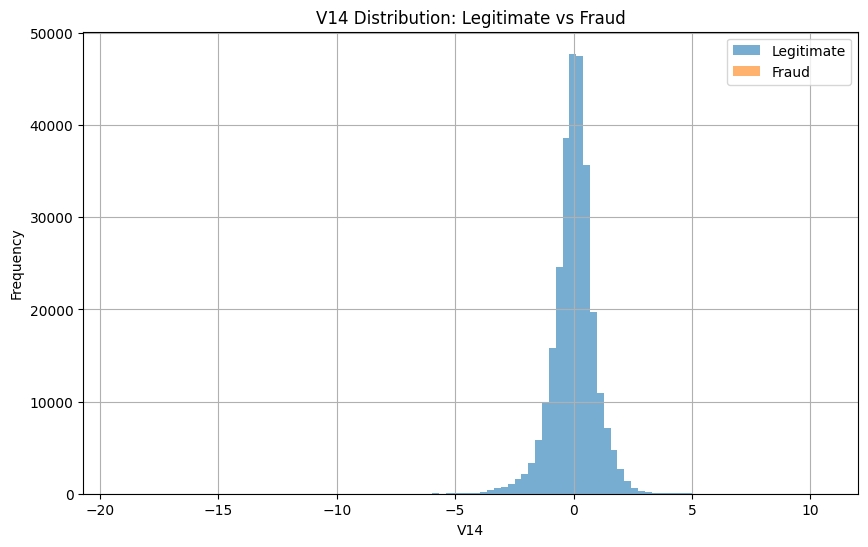

In [59]:
plt.figure(figsize=(10, 6))

data[data["Class"] == 0]["V14"].hist(
    bins=100,
    alpha=0.6,
    label="Legitimate"
)

data[data["Class"] == 1]["V14"].hist(
    bins=100,
    alpha=0.6,
    label="Fraud"
)

plt.xlabel("V14")
plt.ylabel("Frequency")
plt.title("V14 Distribution: Legitimate vs Fraud")
plt.legend()

plt.show()

In [60]:
# Day 8:
# "Feature analysis showed that V14 was the dominant predictive feature in the XGBoost model,
# with substantially different distributions between fraudulent and legitimate transactions."

In [61]:
print(Log_Reg)
print(Random_Forest)
print(XG_Boost)

{'ROC AUC': np.float64(0.8264163044227257), 'PR AUC': np.float64(0.5434010237950423), 'Classification_Report': '              precision    recall  f1-score   support\n\n           0       1.00      1.00      1.00     56864\n           1       0.83      0.65      0.73        98\n\n    accuracy                           1.00     56962\n   macro avg       0.92      0.83      0.87     56962\nweighted avg       1.00      1.00      1.00     56962\n', 'Confusion_MAtrix': array([[56851,    13],
       [   34,    64]])}
{'ROC AUC': np.float64(0.952845062476313), 'PR AUC': np.float64(0.8761509607136012), 'Classification_Report': '              precision    recall  f1-score   support\n\n           0       1.00      1.00      1.00     56864\n           1       0.95      0.82      0.88        98\n\n    accuracy                           1.00     56962\n   macro avg       0.98      0.91      0.94     56962\nweighted avg       1.00      1.00      1.00     56962\n', 'Confusion_MAtrix': array([[56860, 

In [62]:
# We can see how as the depth increases the performance also increaes substancially
# But it increases to a certain limit
# More depth or complex model doesn't equate to better model.

In [63]:
''' learning_rates = [0.01, 0.05, 0.1, 0.2, 0.3]
n_estimators = [100, 200, 300, 400, 500, 600, 700, 800]
depths = [2, 4, 6, 8, 10]


for depth in depths:

    for learning_rate_x in learning_rates:

        for n_estimator_x in n_estimators:

            model = XGBClassifier(
                    n_estimators=n_estimator_x,
                    max_depth=depth, 
                    learning_rate=learning_rate_x,
                    random_state=42,
                    eval_metric="logloss"
                )
            
            model.fit(X_train, Y_train)
            
            prob = model.predict_proba(X_test)[:, 1]
            
            print(     
                    f"estimators = {n_estimator_x} | " 
                    f"max_depth={depth} | "
                    f"learning_rate={learning_rate_x} | "
                    f"ROC-AUC={roc_auc_score(Y_test, prob):.4f} | "
                    f"PR-AUC={average_precision_score(Y_test, prob):.4f}"
                )
     '''
  

' learning_rates = [0.01, 0.05, 0.1, 0.2, 0.3]\nn_estimators = [100, 200, 300, 400, 500, 600, 700, 800]\ndepths = [2, 4, 6, 8, 10]\n\n\nfor depth in depths:\n\n    for learning_rate_x in learning_rates:\n\n        for n_estimator_x in n_estimators:\n\n            model = XGBClassifier(\n                    n_estimators=n_estimator_x,\n                    max_depth=depth, \n                    learning_rate=learning_rate_x,\n                    random_state=42,\n                    eval_metric="logloss"\n                )\n            \n            model.fit(X_train, Y_train)\n            \n            prob = model.predict_proba(X_test)[:, 1]\n            \n            print(     \n                    f"estimators = {n_estimator_x} | " \n                    f"max_depth={depth} | "\n                    f"learning_rate={learning_rate_x} | "\n                    f"ROC-AUC={roc_auc_score(Y_test, prob):.4f} | "\n                    f"PR-AUC={average_precision_score(Y_test, prob):.4f}"\n     

In [64]:
# | max_depth = 10 | learning rate = 0.01 | estimators = 800 | Roc-Auc = 0.9801 | Pr-Auc = 0.8837 |
# from above experiment. Don't run again. Takes an hour.
# The results still cannot be taken seriously as all these are dependent on X_Test as that was used for the validation.
# We will now split the X train and then train the model


In [65]:
X_tr, X_eval, Y_tr, Y_eval =  train_test_split(X_train, Y_train, random_state= 42, test_size= 0.2, stratify= Y_train)

In [66]:
print(X_tr.shape)
print(X_eval.shape)
print(X_test.shape)

print("______________________\n")

print(Y_tr.shape)
print(Y_eval.shape)
print(Y_test.shape)

(182276, 31)
(45569, 31)
(56962, 31)
______________________

(182276,)
(45569,)
(56962,)


In [67]:
configs = [
    (6, 0.01, 600),
    (6, 0.01, 800),
    (8, 0.01, 600),
    (8, 0.01, 800),
    (10, 0.01, 600),
    (10, 0.01, 800),
    (6, 0.05, 400),
    (8, 0.05, 400),
    (10, 0.05, 400)
]


for mx_d, lr, est in configs:


    new_model = XGBClassifier(
        n_estimators = est,
        learning_rate = lr,
        max_depth = mx_d,
        random_state = 42,
        eval_metric = 'logloss'
        )
    
    new_model.fit(X_tr, Y_tr)

    new_prob = new_model.predict_proba(X_eval)[:,1]


    roc_auc_n = roc_auc_score(Y_eval, new_prob)
    pr_auc_n = average_precision_score(Y_eval, new_prob)

    print(f"depth={mx_d} | "
        f"lr={lr} | "
        f"estimators={est} | "
        f"ROC-AUC: {roc_auc_n} |"
        f"PR-AUC: {pr_auc_n} |" )



depth=6 | lr=0.01 | estimators=600 | ROC-AUC: 0.9792515255821979 |PR-AUC: 0.8350001144742127 |
depth=6 | lr=0.01 | estimators=800 | ROC-AUC: 0.977921006425115 |PR-AUC: 0.8339710092415451 |
depth=8 | lr=0.01 | estimators=600 | ROC-AUC: 0.9778134574019606 |PR-AUC: 0.8351685690987612 |
depth=8 | lr=0.01 | estimators=800 | ROC-AUC: 0.9760448116292078 |PR-AUC: 0.8343752426337876 |
depth=10 | lr=0.01 | estimators=600 | ROC-AUC: 0.9744111238803354 |PR-AUC: 0.8333506953318778 |
depth=10 | lr=0.01 | estimators=800 | ROC-AUC: 0.9742065998647638 |PR-AUC: 0.8339387079574225 |
depth=6 | lr=0.05 | estimators=400 | ROC-AUC: 0.973848752403505 |PR-AUC: 0.8335871003608121 |
depth=8 | lr=0.05 | estimators=400 | ROC-AUC: 0.9635649509838022 |PR-AUC: 0.8373721632662227 |
depth=10 | lr=0.05 | estimators=400 | ROC-AUC: 0.9668918749704345 |PR-AUC: 0.8379402119517313 |


In [68]:
# Here best parameters selected are
# max depth = 10,
# learning rate = 0.05,
# estimators = 400
# We will use these parameters to train with X_train and Y_train to get final results


In [69]:
final_model =  XGBClassifier(
    n_estimators = 400,
    learning_rate = 0.05,
    max_depth = 10,
    random_state = 42
)

final_model.fit(X_train, Y_train)
prob = final_model.predict_proba(X_test)[:,1]
final_roc = roc_auc_score(Y_test, prob)
final_auc = average_precision_score(Y_test, prob)

print(f"ROC-AUC: {final_roc}")
print(f"PR-AUC: {final_auc}")


ROC-AUC: 0.9713485738977639
PR-AUC: 0.8747001517159113


In [70]:
pred_final = final_model.predict(X_test)
matric_final = confusion_matrix(Y_test, pred_final)
print(matric_final)

class_repo = classification_report(Y_test, pred_final)
print(class_repo)

[[56857     7]
 [   19    79]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.92      0.81      0.86        98

    accuracy                           1.00     56962
   macro avg       0.96      0.90      0.93     56962
weighted avg       1.00      1.00      1.00     56962



In [71]:
Fin_Model = {"Final_Conf":matric_final,
            "Final_Classi": class_repo,
            "Final_ROC" : final_roc,
            "Final_PRE": final_auc
            }

In [72]:
class_count = Y_tr.value_counts()

negative = class_count[0]
positive = class_count[1]
scale_pos_weight = negative/positive

print(
    f"Legitimate: {negative} | "
    f"Frauds: {positive} | "
    f"Pos Scale: {scale_pos_weight:.4f} | "
    )

Legitimate: 181961 | Frauds: 315 | Pos Scale: 577.6540 | 


In [73]:
# We can see that per 578 transaction there is a fradulent transaction,
# The model itself is performing well, but there is still fradus that cannot be identified
# Depending on the need we might need to fix that, so  we take this weighted pos_scale and train another model with,
# our best parameters and adding the new pos_scale
#  n_estimators = 400,
# learning_rate = 0.05,
# max_depth = 10,
# random_state = 42

In [74]:
Fraud_focused_model = XGBClassifier(
    n_estimators = 400,
    learning_rate = 0.05,
    max_depth = 10,
    random_state = 42,
    scale_pos_weight = 577.65,
    eval_metric = 'logloss')



In [75]:
Fraud_focused_model.fit(X_tr, Y_tr)
weighted_pred = Fraud_focused_model.predict(X_eval)
weighted_proba = Fraud_focused_model.predict_proba(X_eval)[:,1]

In [76]:
print("ROC-AUC:",
      roc_auc_score(Y_eval, weighted_proba))

print("PR-AUC:",
      average_precision_score(Y_eval, weighted_proba))

print("\nConfusion Matrix:")
print(confusion_matrix(Y_eval, weighted_pred))

print("\nClassification Report:")
print(classification_report(Y_eval, weighted_pred))

ROC-AUC: 0.9689298802630151
PR-AUC: 0.8251170165761841

Confusion Matrix:
[[45482     8]
 [   18    61]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     45490
           1       0.88      0.77      0.82        79

    accuracy                           1.00     45569
   macro avg       0.94      0.89      0.91     45569
weighted avg       1.00      1.00      1.00     45569



In [77]:
# Day10:
# We found out that the performance of the model became a little worse
# Both recall and precision are worse
# But we also found out that false positive decreased which might be benificial if detecting the fraud takes priority.
# Even a less precise model will work depending on requirements 

In [78]:
from sklearn.metrics import precision_score, recall_score, f1_score
thresholds = np.arange(0.01, 1.0, 0.01)
results = []

for threshold in thresholds:
    new_prob = (new_prob >= threshold).astype(int)
    precision = precision_score(Y_eval, new_prob)
    recall = recall_score(Y_eval, new_prob)
    f1 = f1_score(Y_eval, new_prob)

    
    results.append(
        (threshold, precision, recall, f1)
    )

best_result = max(results, key=lambda x:x[3])
print("Best threshold:", best_result[0])
print("Precision:", best_result[1])
print("Recall:", best_result[2])
print("F1:", best_result[3])

    

Best threshold: 0.01
Precision: 0.7065217391304348
Recall: 0.8227848101265823
F1: 0.7602339181286549


In [79]:
# We found that the threshold 0.31 gives us the best compromise between our constraints and prioritise catching fraud and still not flag
# all the transactions fraud

In [80]:

y_pred_new= final_model.predict_proba(X_test)[:,1]
threshold_best =0.31
y_prob_threshold = (y_pred_new >= threshold_best).astype(int)

print("Confusion Matrix:")
print(confusion_matrix(Y_test,y_prob_threshold))

print("\nClassification Report:")
print(classification_report(Y_test, y_prob_threshold))

print("Precision:", precision_score(Y_test, y_prob_threshold))
print("Recall:", recall_score(Y_test, y_prob_threshold))
print("F1:", f1_score(Y_test,y_prob_threshold))

Confusion Matrix:
[[56855     9]
 [   17    81]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.90      0.83      0.86        98

    accuracy                           1.00     56962
   macro avg       0.95      0.91      0.93     56962
weighted avg       1.00      1.00      1.00     56962

Precision: 0.9
Recall: 0.826530612244898
F1: 0.8617021276595744


In [81]:
# Day 11:
# Our model using XGBoost is ready. It has a decent recall and precision score.
# Threshold can be altered to satisfy certain needs.
Y_train



,Class
265518,0
180305,0
42664,0
198723,0
82325,0
...,...
233802,0
85418,0
29062,0
13766,0


In [82]:
from sklearn.ensemble import IsolationForest
fraud_rate = Y_train.mean()
fraud_rate

np.float64(0.001729245759178389)

In [83]:
contamination_values =  [0.001, 0.0017, 0.003, 0.005, 0.01]
for c in contamination_values:
    iso_mode = IsolationForest(
        n_estimators=200,
        random_state=42,
        contamination=c,
        n_jobs=1
        )

    iso_mode.fit(X_train)
    predictions = iso_mode.predict(X_test)
    anomalies = (predictions == -1).astype(int)

    precision = precision_score(Y_test, anomalies, zero_division=0)
    recall = recall_score(Y_test, anomalies)
    f1 = f1_score(Y_test, anomalies)

    print(
        f"contamination={c:.4f} | "
        f"precision={precision:.3f} | "
        f"recall={recall:.3f} | "
        f"F1={f1:.3f}"
    )
   

contamination=0.0010 | precision=0.323 | recall=0.214 | F1=0.258
contamination=0.0017 | precision=0.308 | recall=0.327 | F1=0.317
contamination=0.0030 | precision=0.230 | recall=0.378 | F1=0.286
contamination=0.0050 | precision=0.162 | recall=0.490 | F1=0.244
contamination=0.0100 | precision=0.109 | recall=0.694 | F1=0.189


In [84]:
# Isolation Forest was evaluated as an unsupervised anomaly-detection approach.
# Different contamination levels were tested to investigate the precision-recall trade-off.
# At the dataset's approximate fraud rate of 0.17%, the model achieved 30.8% precision,
# 32.7% recall, and 31.7% F1 on the test set. Increasing contamination to 1% raised recall to 69.4%, but precision dropped to 10.9%.
# The supervised XGBoost model substantially outperformed Isolation Forest on this dataset.

In [85]:
# Model That we will use = final_model

In [86]:
import joblib
import os

joblib.dump(final_model, "fraud_model.pkl")
joblib.dump(scaler, "scaler.pkl")



['scaler.pkl']

In [87]:

loaded_model = joblib.load("fraud_model.pkl")
loaded_scaler = joblib.load("scaler.pkl")


In [88]:
THRESHOLD = 0.31 # As we got before

def Fraud_Detect(transaction):

    data = pd.DataFrame([transaction])

    #feature adding
    data['LogAmount'] = np.log1p(data['Amount'])

    columns_to_scale = ['Time', 'Amount', 'LogAmount'] # Same order used while preprocessing

    # Scaling the three columns with the exact scaler used before
    data[columns_to_scale] = loaded_scaler.transform(data[columns_to_scale])

    

    # Makes sure the features are in correct order
    data =  data[final_model.get_booster().feature_names]

    # Get Fraud Probability
    fraud_probability = loaded_model.predict_proba(data)[0,1]

    # Apply threshold
    prediction = int(fraud_probability >= THRESHOLD)

    return {
        "fraud_probability": float(fraud_probability),
        "threshold": THRESHOLD,
        "prediction": "Fraud" if prediction == 1 else "Legitimate"
    }


    

In [91]:
raw_transaction = data.drop("Class", axis=1).iloc[0].to_dict()
print(raw_transaction)

{'Time': 0.0, 'V1': -1.3598071336738, 'V2': -0.0727811733098497, 'V3': 2.53634673796914, 'V4': 1.37815522427443, 'V5': -0.338320769942518, 'V6': 0.462387777762292, 'V7': 0.239598554061257, 'V8': 0.0986979012610507, 'V9': 0.363786969611213, 'V10': 0.0907941719789316, 'V11': -0.551599533260813, 'V12': -0.617800855762348, 'V13': -0.991389847235408, 'V14': -0.311169353699879, 'V15': 1.46817697209427, 'V16': -0.470400525259478, 'V17': 0.207971241929242, 'V18': 0.0257905801985591, 'V19': 0.403992960255733, 'V20': 0.251412098239705, 'V21': -0.018306777944153, 'V22': 0.277837575558899, 'V23': -0.110473910188767, 'V24': 0.0669280749146731, 'V25': 0.128539358273528, 'V26': -0.189114843888824, 'V27': 0.133558376740387, 'V28': -0.0210530534538215, 'Amount': 149.62}


In [92]:
print(loaded_model.get_booster().feature_names)

['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'LogAmount']


In [94]:
result = Fraud_Detect(raw_transaction)

print(result)

{'fraud_probability': 8.420832273259293e-06, 'threshold': 0.31, 'prediction': 'Legitimate'}
